# 08 · Figures for the micropublication
> Run after notebooks 01–07, from inside the `code` folder. **This notebook draws the figure panels of the
> micropublication** (`micropublication/main_five_panels_grid.tex`); it does no new analysis. Every number is read
> from the result tables that notebooks 03, 05 and 07 wrote to `output/`, and the CAAR line uses the same
> `plot_caar` function from `buzzword_event_study.py` as notebook 03, so the panels match the analysis exactly.

**Micropublication requirements followed here** (author guidelines):

* one figure with **at most five panels** (Figure 1, panels A–E), cited in the Results as [Fig. 1A] … [Fig. 1E] in order;
* each panel is a **separate image file**;
* **no titles or panel letters inside the images** (the letters, the caption and the panel titles are set in LaTeX);
* each panel is uploaded to cloud storage and linked in the PDF with its title.

| Panel | Content | Analysis figure it is drawn from | Source table |
|---|---|---|---|
| Figure 1 | Buzzword renames per 1,000 listed firms, 1990–2025 | `rq1_rebranding_prevalence.png`, left panel (NB 03) | `core_analysis_results.xlsx` · `B_theme_year` |
| Figure 2 | Abnormal returns over three and eleven days, 95% CI | `overview_results_at_a_glance.png` (NB 07) | `core_analysis_results.xlsx` · `rq2_event_study`; `confounding_sensitivity_results.xlsx` · `by_deal_type`; `control_group_results.xlsx` · `thematic_minus_control` |
| Figure 3 | Cumulative abnormal return day by day around the announcement | `rq2_event_study_caar.png`, left panel (NB 03) | `core_analysis_results.xlsx` · `rq2_daily_abnormal`, `A_event_level` |
| Figure 4 | Size, profitability and balance sheet vs. other firms | `rq4_firm_characteristics.png` (NB 03) | `core_analysis_results.xlsx` · `rq4_characteristics` |
| Figure 5 | Industry of rebranding firms vs. other firms | `rq4_industry_mix.png` (NB 03) | `core_analysis_results.xlsx` · `rq4_industry` |

The analysis figures in `output/` keep their titles and multi-panel layouts for the notebooks; the panels here
are redrawn as single panels without titles. Files are written to `output/` with the prefix **`micropub_`** (e.g. `output/micropub_figure1_prevalence.png`), so
they sit next to the analysis figures but are clearly marked as micropublication panels: PNG (300 dpi, for upload)
and PDF (vector, for LaTeX).

The notebook has two parts:

* **Part 1** draws the five panels as single figures at half-page width (`output/micropub_figure*`).
* **Part 2** redraws the same five panels at their printed size for Figure 1 of the micropublication
  (`output/micropub_grid_figure*`, copied to `micropublication/figures/` as `grid_*.pdf`): A–D in a 2 × 2 grid,
  E upright on the right over both rows. It reuses the tables read in Part 1.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import buzzword_event_study as es

base_dir = Path.cwd().parent                                  # project folder (the notebooks run from code/)
output_dir = base_dir / "output"
figure_dir = output_dir                      # saved next to the analysis figures, prefixed "micropub_" (Part 1)
                                             # and "micropub_grid_" (Part 2)

themes = ["Dot-com", "Blockchain", "AI"]
theme_colors = {"Dot-com": "#2a78b5", "Blockchain": "#e08a1e", "AI": "#3a9e5f"}
theme_markers = {"Dot-com": "o", "Blockchain": "s", "AI": "^"}   # second encoding besides colour
wave_periods = {"Dot-com": (1995, 2002), "Blockchain": (2016, 2020), "AI": (2021, 2025)}
ink, muted, grid = "#222222", "#666666", "#e6e6e6"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5,   # compact panels: shown two per row in the PDF
                     "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.edgecolor": "#999999",
                     "axes.labelcolor": ink, "xtick.color": muted, "ytick.color": muted})

core_path = output_dir / "core_analysis_results.xlsx"


def save_panel(fig, name):
    """
    Save one figure panel as PNG (300 dpi) and PDF, without any title inside the image.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
    name : str
        File name without extension and without the ``micropub_`` prefix.
    """
    fig.tight_layout()
    for extension in ("png", "pdf"):
        fig.savefig(figure_dir / f"micropub_{name}.{extension}", dpi=300, bbox_inches="tight")
    plt.show()

# Part 1 · Single panels at half-page width

## Figure 1: prevalence
Renames per 1,000 listed firms by the year the new name took effect, 1990–2025 (left panel of
`rq1_rebranding_prevalence.png`). The wave periods are shaded; each line is labelled directly, so no legend box.

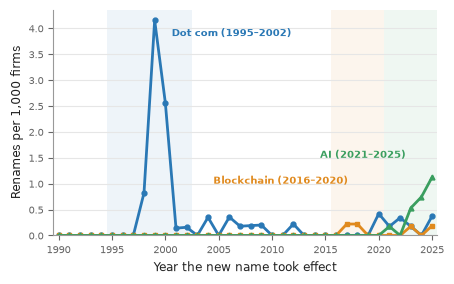

In [2]:
theme_year = pd.read_excel(core_path, sheet_name="B_theme_year")
fig, ax = plt.subplots(figsize=(4.6, 2.9))
for theme in themes:
    first, last = wave_periods[theme]
    ax.axvspan(first - 0.5, last + 0.5, color=theme_colors[theme], alpha=0.08, lw=0)
    sub = theme_year[theme_year["theme"] == theme]
    ax.plot(sub["year"], sub["intensity_per_1000"], color=theme_colors[theme], lw=2,
            marker=theme_markers[theme], ms=3.5)
    label_position = {"Dot-com": (2000.6, 3.85), "Blockchain": (2004.5, 1.0), "AI": (2014.5, 1.5)}
    ax.text(*label_position[theme], f"{theme.replace('Dot-com', 'Dot com')} ({first}–{last})", color=theme_colors[theme], fontsize=7.5,
            weight="bold")
ax.set_xlabel("Year the new name took effect")
ax.set_ylabel("Renames per 1,000 firms")
ax.set_xlim(1989.5, 2025.5)
ax.set_ylim(0, None)
ax.grid(axis="y", color=grid)
ax.spines[["top", "right"]].set_visible(False)
save_panel(fig, "figure1_prevalence")

## Figure 2: abnormal returns at a glance
The four rows of `overview_results_at_a_glance.png` (notebook 07), with both windows in one panel: filled markers
for three days [−1,+1], open markers for eleven days [−5,+5]. The last row is the difference between dot com renames
and ordinary (non-buzzword, non-SPAC) renames of the wave years, both dated at the legal effective date
(notebook 05). The two blockchain events are case studies and are not averaged.

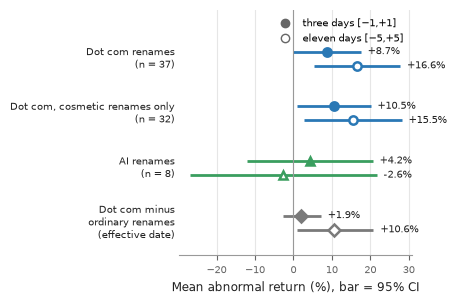

In [3]:
core = pd.read_excel(core_path, sheet_name="rq2_event_study")
deals = pd.read_excel(output_dir / "confounding_sensitivity_results.xlsx", sheet_name="by_deal_type")
control = pd.read_excel(output_dir / "control_group_results.xlsx", sheet_name="thematic_minus_control")


def glance_row(label, measure):
    """
    Return n, mean and 95% interval of one row of the results-at-a-glance figure.

    Parameters
    ----------
    label : str
        Row of the figure.
    measure : str
        ``car_m1_p1`` or ``car_m5_p5``.

    Returns
    -------
    pandas.Series
        ``n``, ``mean``, ``ci_low``, ``ci_high``.
    """
    if label == "Dot com renames":
        r = core[(core["sample"] == "Dot-com (primary)") & (core["measure"] == measure)].iloc[0]
    elif label == "Dot com, cosmetic renames only":
        r = deals[(deals["wave"] == "Dot-com") & (deals["deal_type"] == "a cosmetic")
                  & (deals["measure"] == measure)].iloc[0]
    elif label == "AI renames":
        r = core[(core["sample"] == "AI (primary)") & (core["measure"] == measure)].iloc[0]
    else:                                       # same specification as notebook 07: "A: cosmetic/pivot vs non-SPAC"
        r = control[control["specification"].str.startswith("A:") & (control["wave"] == "Dot-com")
                    & (control["outcome"] == measure)].iloc[0]
        return pd.Series({"n": r["n_thematic"], "mean": r["difference"], "ci_low": r["boot_ci_low"],
                          "ci_high": r["boot_ci_high"]})
    return r[["n", "mean", "ci_low", "ci_high"]]


rows = [("Dot com renames", theme_colors["Dot-com"], theme_markers["Dot-com"]),
        ("Dot com, cosmetic renames only", theme_colors["Dot-com"], theme_markers["Dot-com"]),
        ("AI renames", theme_colors["AI"], theme_markers["AI"]),
        ("Dot com minus\nordinary renames\n(effective date)", "#7a7a7a", "D")]
fig, ax = plt.subplots(figsize=(4.6, 3.1))
for y, (label, color, marker) in enumerate(rows[::-1]):
    for offset, measure, filled in [(0.13, "car_m1_p1", True), (-0.13, "car_m5_p5", False)]:
        r = glance_row(label, measure)
        ax.hlines(y + offset, r["ci_low"] * 100, r["ci_high"] * 100, color=color, lw=2)
        ax.plot(r["mean"] * 100, y + offset, marker=marker, ms=6, color=color,
                markerfacecolor=color if filled else "white", markeredgewidth=1.8)
        ax.annotate(f"{r['mean'] * 100:+.1f}%", (r["ci_high"] * 100, y + offset), xytext=(5, 0),
                    textcoords="offset points", va="center", fontsize=7, color=ink)
    n_label = "" if label.startswith("Dot com minus") else f"\n(n = {int(glance_row(label, 'car_m1_p1')['n'])})"
    ax.text(-0.02, y, label + n_label, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=7.5,
            color=ink)
ax.axvline(0, color="#999999", lw=0.8)
ax.set_yticks([])
ax.set_ylim(-0.6, len(rows) - 0.1)
ax.set_xlabel("Mean abnormal return (%), bar = 95% CI")
ax.plot([], [], "o", color=muted, label="three days [−1,+1]")
ax.plot([], [], "o", color=muted, markerfacecolor="white", label="eleven days [−5,+5]")
ax.legend(frameon=False, loc="upper right", fontsize=7)
ax.grid(axis="x", color=grid)
ax.spines[["top", "right", "left"]].set_visible(False)
save_panel(fig, "figure2_abnormal_returns")

## Figure 3: abnormal return day by day
Cumulative average abnormal return (95% CI) from ten trading days before to ten after the first public
announcement, for primary-sample events with a complete [−10,+10] window: the left panel of
`rq2_event_study_caar.png`, drawn with the same `es.plot_caar` call as notebook 03. It shows why the eleven-day
return is larger than the three-day return: prices start rising before day 0. The volume panel of the analysis
figure is not repeated (five-panel limit); the volume result is reported in the text.

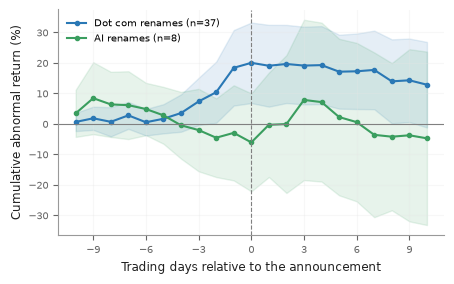

In [4]:
abnormal = pd.read_excel(core_path, sheet_name="rq2_daily_abnormal")
event_level = pd.read_excel(core_path, sheet_name="A_event_level")
primary = event_level[(event_level["primary_sample"] == 1) & (event_level["theme"] != "Blockchain")]
fig, ax = plt.subplots(figsize=(4.6, 2.9))
es.plot_caar(abnormal, primary, "theme", {"Dot-com": theme_colors["Dot-com"], "AI": theme_colors["AI"]}, ax)
ax.set_title("")                                   # no titles inside micropublication panels
ax.set_xlabel("Trading days relative to the announcement")
ax.set_ylabel("Cumulative abnormal return (%)")
for line in ax.get_lines():
    line.set_label(line.get_label().replace("Dot-com", "Dot com renames").replace("AI (", "AI renames ("))
ax.legend(frameon=False, loc="upper left", fontsize=7)
ax.grid(color=grid)
ax.spines[["top", "right"]].set_visible(False)
save_panel(fig, "figure3_daily_abnormal_returns")

## Figure 4: who rebrands
The characteristics in `rq4_firm_characteristics.png` (notebook 03) as one panel: the standardised difference
(difference in means / pooled standard deviation) between in-wave rebranding firms and non-rebranding firms of the
same fiscal years, from accounts public at least six months before the event. Negative values: rebranding firms
have less of it. Blockchain (2 firms) is not shown.

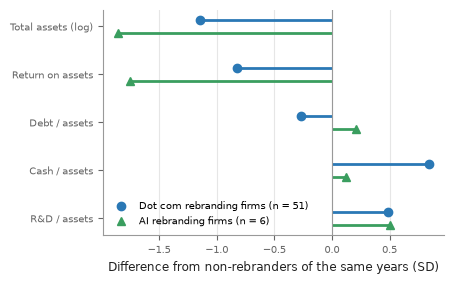

In [5]:
characteristics = pd.read_excel(core_path, sheet_name="rq4_characteristics")
labels = {"log_assets": "Total assets (log)", "roa": "Return on assets", "leverage": "Debt / assets",
          "cash_to_assets": "Cash / assets", "rd_to_assets": "R&D / assets"}
fig, ax = plt.subplots(figsize=(4.6, 2.9))
for offset, theme in zip([0.14, -0.14], ["Dot-com", "AI"]):
    sub = characteristics[characteristics["comparison"] == f"{theme} rebranders vs. same-year non-rebranders"]
    sub = sub.set_index("characteristic").loc[list(labels)]
    positions = np.arange(len(labels))[::-1] + offset
    ax.hlines(positions, 0, sub["std_difference"], color=theme_colors[theme], lw=2)
    n_firms = int(sub.loc["log_assets", "n_rebranders"])
    ax.plot(sub["std_difference"], positions, theme_markers[theme], ms=6, color=theme_colors[theme],
            label=f"{theme.replace('Dot-com', 'Dot com')} rebranding firms (n = {n_firms})")
ax.axvline(0, color="#999999", lw=0.8)
ax.set_yticks(np.arange(len(labels))[::-1], list(labels.values()), fontsize=7.5)
ax.set_xlabel("Difference from non-rebranders of the same years (SD)")
ax.legend(frameon=False, loc="lower left", fontsize=7)   # empty corner: no bars there
ax.grid(axis="x", color=grid)
ax.spines[["top", "right"]].set_visible(False)
save_panel(fig, "figure4_firm_characteristics")

## Figure 5: industry of rebranding firms
The groups of `rq4_industry_mix.png` (notebook 03): share of in-wave rebranding firms in each Fama-French 12
industry, for the dot com and AI waves, against all other listed firms of the same fiscal years (renamed or not;
dark grey: dot com years, light grey: AI years). Industries below 3% in every group are combined as
"Other industries".

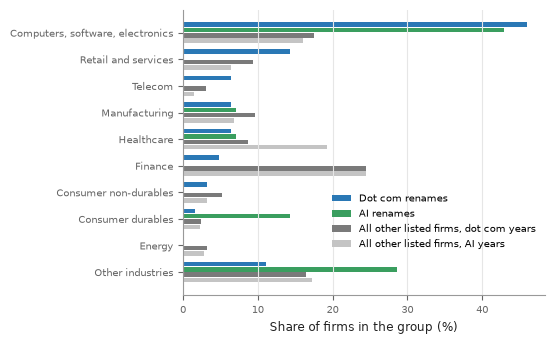

,Dot com renames,AI renames,"All other listed firms, dot com years","All other listed firms, AI years"
Other industries,11.1,28.6,16.4,17.3
Energy,0.0,0.0,3.2,2.8
Consumer durables,1.6,14.3,2.4,2.3
Consumer non-durables,3.2,0.0,5.3,3.2
Finance,4.8,0.0,24.4,24.5
Healthcare,6.3,7.1,8.7,19.2
Manufacturing,6.3,7.1,9.7,6.8
Telecom,6.3,0.0,3.0,1.4
Retail and services,14.3,0.0,9.4,6.5
"Computers, software, electronics",46.0,42.9,17.5,16.0


In [6]:
industry = pd.read_excel(core_path, sheet_name="rq4_industry")
short = {"BusEq": "Computers, software, electronics", "Shops": "Retail and services", "Telcm": "Telecom",
         "Hlth": "Healthcare", "Manuf": "Manufacturing", "Money": "Finance", "Durbl": "Consumer durables",
         "NoDur": "Consumer non-durables", "Chems": "Chemicals", "Enrgy": "Energy", "Utils": "Utilities"}
industry["label"] = industry["industry"].str.split().str[0].map(short).fillna("Other industries")
groups = {"Dot com renames": ("Dot-com", "share_rebranders", theme_colors["Dot-com"]),
          "AI renames": ("AI", "share_rebranders", theme_colors["AI"]),
          "All other listed firms, dot com years": ("Dot-com", "share_same_year_others", "#7a7a7a"),
          "All other listed firms, AI years": ("AI", "share_same_year_others", "#c4c4c4")}
shares = pd.DataFrame({name: industry[industry["wave"] == wave].groupby("label")[column].sum()
                       for name, (wave, column, _) in groups.items()}).fillna(0)
small = shares.max(axis=1) < 0.03
other = shares[small | (shares.index == "Other industries")].sum().rename("Other industries")
shares = shares[~small & (shares.index != "Other industries")].sort_values("Dot com renames")
shares = pd.concat([other.to_frame().T, shares])   # first row = bottom of the chart
fig, ax = plt.subplots(figsize=(5.6, 3.5))
height = 0.2
for i, (name, (_, _, color)) in enumerate(groups.items()):
    positions = [y + (1.5 - i) * height for y in range(len(shares))]
    ax.barh(positions, shares[name] * 100, height=height - 0.03, color=color, label=name)
ax.set_yticks(range(len(shares)), shares.index, fontsize=7.5)
ax.set_xlabel("Share of firms in the group (%)")
ax.legend(frameon=False, fontsize=7, loc="lower right", bbox_to_anchor=(1, 0.13))   # rows under it end below 15%
ax.grid(axis="x", color=grid)
ax.spines[["top", "right"]].set_visible(False)
save_panel(fig, "figure5_industry")
(shares * 100).round(1)

# Part 2 · Panels of Figure 1 in the micropublication (`main_five_panels_grid.tex`)
In the micropublication Figure 1 has at most two rows: panels A–D in a 2 × 2 grid on the left and panel E
on the right, spanning both rows. The Part 1 panels are drawn for a half-page width; printed four to a row their
labels would become too small. Here each panel is drawn at its printed size (the saved size is exactly the figure
size, so all panels print at the same scale) and panel E is drawn upright to fill the height of the two rows.
Content and numbers are the same as in Part 1; only sizes, label lengths and legend positions differ. Panel B has no
legend: the caption explains filled (three days) and open (eleven days) markers.

| Panel | Content | Printed size (inches) |
|---|---|---|
| A | Buzzword renames per 1,000 listed firms, 1990–2025 | 2.05 × 1.5 |
| B | Abnormal returns over three and eleven days, 95% CI | 2.05 × 1.5 |
| C | Cumulative abnormal return day by day around the announcement | 2.05 × 1.5 |
| D | Size, profitability and balance sheet vs. other firms | 2.05 × 1.5 |
| E | Industry of rebranding firms vs. other firms | 2.0 × 3.25 |

In [7]:
plt.rcParams.update({"font.size": 6.5, "xtick.labelsize": 5.8, "ytick.labelsize": 5.8,   # drawn at printed size
                     "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.labelpad": 2})
small_panel = (2.05, 1.5)                    # panels A-D, two per row on the left
tall_panel = (2.0, 3.25)                     # panel E, on the right over both rows


def save_grid_panel(fig, name, margins):
    """
    Save one panel of the two-row layout as PNG (300 dpi) and PDF, without any title inside the image.

    The saved size is exactly the figure size, so all panels print at the same scale; the margins are set by hand
    so that the axis labels fit inside the image.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
    name : str
        File name without extension and without the ``micropub_grid_`` prefix.
    margins : dict
        ``left``, ``right``, ``bottom`` and ``top`` of the plot area as fractions of the figure.
    """
    fig.subplots_adjust(**margins)
    for extension in ("png", "pdf"):
        fig.savefig(figure_dir / f"micropub_grid_{name}.{extension}", dpi=300)
    plt.show()

## Panel A (grid): prevalence

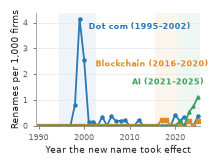

In [8]:
fig, ax = plt.subplots(figsize=small_panel)
for theme in themes:
    first, last = wave_periods[theme]
    ax.axvspan(first - 0.5, last + 0.5, color=theme_colors[theme], alpha=0.08, lw=0)
    sub = theme_year[theme_year["theme"] == theme]
    ax.plot(sub["year"], sub["intensity_per_1000"], color=theme_colors[theme], lw=1.3,
            marker=theme_markers[theme], ms=2.2)
    label_position = {"Dot-com": (2001.0, 3.75), "Blockchain": (2002.5, 2.3), "AI": (2010.5, 1.6)}
    ax.text(*label_position[theme], f"{theme.replace('Dot-com', 'Dot com')} ({first}–{last})",
            color=theme_colors[theme], fontsize=5.5, weight="bold")
ax.set_xlabel("Year the new name took effect")
ax.set_ylabel("Renames per 1,000 firms")
ax.set_xlim(1989.5, 2025.5)
ax.set_xticks([1990, 2000, 2010, 2020])
ax.set_ylim(0, None)
ax.grid(axis="y", color=grid, lw=0.5)
ax.spines[["top", "right"]].set_visible(False)
save_grid_panel(fig, "figure1_prevalence", {"left": 0.17, "right": 0.97, "bottom": 0.22, "top": 0.97})

## Panel B (grid): abnormal returns at a glance
Same rows as Figure 2 (`glance_row` from Part 1), with shorter row labels.

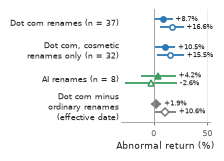

In [9]:
grid_rows = [("Dot com renames", "Dot com renames", theme_colors["Dot-com"], theme_markers["Dot-com"]),
             ("Dot com, cosmetic renames only", "Dot com, cosmetic\nrenames only", theme_colors["Dot-com"],
              theme_markers["Dot-com"]),
             ("AI renames", "AI renames", theme_colors["AI"], theme_markers["AI"]),
             (rows[3][0], rows[3][0], "#7a7a7a", "D")]          # (row of glance_row, label shown, colour, marker)
fig, ax = plt.subplots(figsize=small_panel)
for y, (key, label, color, marker) in enumerate(grid_rows[::-1]):
    for offset, measure, filled in [(0.14, "car_m1_p1", True), (-0.14, "car_m5_p5", False)]:
        r = glance_row(key, measure)
        ax.hlines(y + offset, r["ci_low"] * 100, r["ci_high"] * 100, color=color, lw=1.3)
        ax.plot(r["mean"] * 100, y + offset, marker=marker, ms=3.8, color=color,
                markerfacecolor=color if filled else "white", markeredgewidth=1.1)
        ax.annotate(f"{r['mean'] * 100:+.1f}%", (r["ci_high"] * 100, y + offset), xytext=(2, 0),
                    textcoords="offset points", va="center", fontsize=5, color=ink)
    n_label = "" if key.startswith("Dot com minus") else f" (n = {int(glance_row(key, 'car_m1_p1')['n'])})"
    ax.text(-0.03, y, label + n_label, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=5.5,
            color=ink)
ax.axvline(0, color="#999999", lw=0.6)
ax.set_yticks([])
ax.set_ylim(-0.5, len(grid_rows) - 0.5)
ax.set_xlim(-30, 52)                         # room for the value labels right of the intervals
ax.set_xlabel("Abnormal return (%)")
ax.grid(axis="x", color=grid, lw=0.5)
ax.spines[["top", "right", "left"]].set_visible(False)
save_grid_panel(fig, "figure2_abnormal_returns", {"left": 0.54, "right": 0.97, "bottom": 0.22, "top": 0.97})

## Panel C (grid): abnormal return day by day

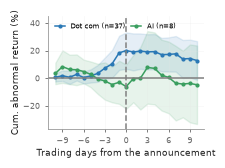

In [10]:
fig, ax = plt.subplots(figsize=small_panel)
es.plot_caar(abnormal, primary, "theme", {"Dot-com": theme_colors["Dot-com"], "AI": theme_colors["AI"]}, ax)
ax.set_title("")                                   # no titles inside micropublication panels
ax.set_xlabel("Trading days from the announcement")
ax.set_ylabel("Cum. abnormal return (%)")
for line in ax.get_lines():
    line.set_linewidth(1.1)
    line.set_markersize(2)
    line.set_label(line.get_label().replace("Dot-com", "Dot com"))
ax.set_ylim(None, 45)                              # room for the legend above the bands
ax.legend(frameon=False, loc="upper left", fontsize=5, handlelength=1.5, ncol=2, columnspacing=0.8)
ax.grid(color=grid, lw=0.5)
ax.spines[["top", "right"]].set_visible(False)
save_grid_panel(fig, "figure3_daily_abnormal_returns", {"left": 0.21, "right": 0.97, "bottom": 0.22, "top": 0.97})

## Panel D (grid): who rebrands

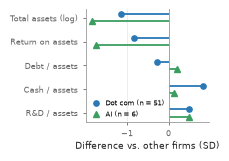

In [11]:
fig, ax = plt.subplots(figsize=small_panel)
for offset, theme in zip([0.15, -0.15], ["Dot-com", "AI"]):
    sub = characteristics[characteristics["comparison"] == f"{theme} rebranders vs. same-year non-rebranders"]
    sub = sub.set_index("characteristic").loc[list(labels)]
    positions = np.arange(len(labels))[::-1] + offset
    ax.hlines(positions, 0, sub["std_difference"], color=theme_colors[theme], lw=1.3)
    n_firms = int(sub.loc["log_assets", "n_rebranders"])
    ax.plot(sub["std_difference"], positions, theme_markers[theme], ms=3.8, color=theme_colors[theme],
            label=f"{theme.replace('Dot-com', 'Dot com')} (n = {n_firms})")
ax.axvline(0, color="#999999", lw=0.6)
ax.set_yticks(np.arange(len(labels))[::-1], list(labels.values()), fontsize=5.5)
ax.set_xlabel("Difference vs. other firms (SD)")
ax.legend(frameon=False, loc="lower left", fontsize=5, handletextpad=0.3, borderaxespad=0.1)   # empty corner
ax.grid(axis="x", color=grid, lw=0.5)
ax.spines[["top", "right"]].set_visible(False)
save_grid_panel(fig, "figure4_firm_characteristics", {"left": 0.37, "right": 0.97, "bottom": 0.22, "top": 0.97})

## Panel E (grid): industry of rebranding firms, upright over both rows
The `shares` table of Figure 5, with long industry names wrapped and shorter group names; the legend sits below the bars.

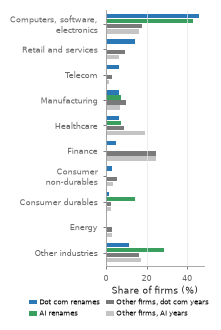

In [12]:
grid_shares = shares.rename(index={"Computers, software, electronics": "Computers, software,\nelectronics",
                                   "Consumer non-durables": "Consumer\nnon-durables"})
grid_names = {"Dot com renames": "Dot com renames", "AI renames": "AI renames",
              "All other listed firms, dot com years": "Other firms, dot com years",
              "All other listed firms, AI years": "Other firms, AI years"}
fig, ax = plt.subplots(figsize=tall_panel)
height = 0.2
for i, (name, (_, _, color)) in enumerate(groups.items()):
    positions = [y + (1.5 - i) * height for y in range(len(grid_shares))]
    ax.barh(positions, grid_shares[name] * 100, height=height - 0.03, color=color, label=grid_names[name])
ax.set_yticks(range(len(grid_shares)), grid_shares.index, fontsize=5.5)
ax.set_ylim(-0.55, len(grid_shares) - 0.45)
ax.set_xlabel("Share of firms (%)")
ax.legend(frameon=False, fontsize=5, loc="upper left", bbox_to_anchor=(-0.85, -0.1), ncol=2,
          handlelength=1.2, handletextpad=0.3, columnspacing=0.8)   # below the bars, across the panel width
ax.grid(axis="x", color=grid, lw=0.5)
ax.spines[["top", "right"]].set_visible(False)
save_grid_panel(fig, "figure5_industry", {"left": 0.47, "right": 0.96, "bottom": 0.2, "top": 0.99})

## Panel titles for the LaTeX file and the panel links
The images contain no titles. The caption of Figure 1 in `micropublication/main_five_panels_grid.tex` describes
each panel; the panel links carry these short titles:

* **A** Buzzword renames per 1,000 listed firms
* **B** Abnormal returns around the announcement
* **C** Cumulative abnormal return by trading day
* **D** Rebranding firms vs. other firms
* **E** Industry mix of rebranding firms